In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu128
GPU available: True
GPU: Tesla T4


In [ ]:
!pip install -q opencv-python scikit-learn matplotlib seaborn pandas

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [ ]:
import os

folders = [
    "dataset",
    "models",
    "results",
    "embeddings"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created.")

Project folders created.


In [ ]:
import os

os.makedirs("/content/celeba", exist_ok=True)

print("Folder ready!")

Folder ready!


In [ ]:
!wget -q --show-progress \
"https://huggingface.co/datasets/Yuehao/celeba/resolve/main/img_align_celeba.zip" \
-O /content/celeba/img_align_celeba.zip

/content/celeba/img 100%[===================>]   1.34G  63.5MB/s    in 19s     


In [ ]:
!wget -q \
"https://huggingface.co/datasets/Yuehao/celeba/resolve/main/identity_CelebA.txt" \
-O /content/celeba/identity_CelebA.txt

In [ ]:
!wget -q \
"https://huggingface.co/datasets/Yuehao/celeba/resolve/main/list_eval_partition.txt" \
-O /content/celeba/list_eval_partition.txt

In [ ]:
import os

print(os.listdir("/content/celeba"))

['list_eval_partition.txt', 'img_align_celeba.zip', 'identity_CelebA.txt']


In [ ]:
import pandas as pd

identity_file = "/content/celeba/identity_CelebA.txt"

identity_df = pd.read_csv(
    identity_file,
    sep=" ",
    header=None,
    names=["image", "identity"]
)

print(identity_df.head())
print()
print("Total images:", len(identity_df))
print("Unique identities:", identity_df["identity"].nunique())

        image  identity
0  000001.jpg      2880
1  000002.jpg      2937
2  000003.jpg      8692
3  000004.jpg      5805
4  000005.jpg      9295

Total images: 202599
Unique identities: 10177


In [ ]:
identity_counts = identity_df["identity"].value_counts()

print("Identity counts calculated successfully.")

Identity counts calculated successfully.


In [ ]:
print("Identities with at least 20 images:",
      (identity_counts >= 20).sum())

print("Identities with at least 30 images:",
      (identity_counts >= 30).sum())

print("Identities with at least 40 images:",
      (identity_counts >= 40).sum())

Identities with at least 20 images: 6348
Identities with at least 30 images: 2360
Identities with at least 40 images: 0


In [ ]:
import os

base_dir = "/content/face_dataset"

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "val")
test_dir = os.path.join(base_dir, "test")

for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)

print("Dataset folders created!")

Dataset folders created!


In [ ]:
# select identities

import random

# Identities having at least 30 images
eligible_identities = identity_counts[
    identity_counts >= 30
].index.tolist()

# Fixed seed for reproducibility
random.seed(42)

# Select 100 identities
selected_identities = random.sample(
    eligible_identities,
    100
)

print("Selected identities:", len(selected_identities))
print("First 10 identities:", selected_identities[:10])

Selected identities: 100
First 10 identities: [2805, 9155, 8704, 4808, 5096, 3857, 2863, 8701, 4721, 1634]


In [ ]:
# select 30 pics for each identity

selected_data = identity_df[
    identity_df["identity"].isin(selected_identities)
].copy()

# Randomize images within each identity
selected_data = (
    selected_data
    .groupby("identity", group_keys=False)
    .apply(lambda x: x.sample(n=30, random_state=42))
    .reset_index(drop=True)
)

print("Total selected images:", len(selected_data))
print("Number of identities:", selected_data["identity"].nunique())

Total selected images: 3000
Number of identities: 100


/tmp/ipykernel_2647/1525242358.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(n=30, random_state=42))


In [ ]:
train_data = []
val_data = []
test_data = []

for identity in selected_identities:

    person_images = selected_data[
        selected_data["identity"] == identity
    ].sample(frac=1, random_state=42)

    train_data.extend(
        person_images.iloc[:20].to_dict("records")
    )

    val_data.extend(
        person_images.iloc[20:25].to_dict("records")
    )

    test_data.extend(
        person_images.iloc[25:30].to_dict("records")
    )

print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))

Training images: 2000
Validation images: 500
Testing images: 500


In [ ]:
import zipfile
import shutil

zip_path = "/content/celeba/img_align_celeba.zip"

def extract_images(data, destination):

    with zipfile.ZipFile(zip_path, "r") as zip_ref:

        for item in data:

            filename = item["image"]
            identity = str(item["identity"])

            # Create identity folder
            identity_folder = os.path.join(
                destination,
                identity
            )

            os.makedirs(
                identity_folder,
                exist_ok=True
            )

            # Find image inside ZIP
            zip_filename = "img_align_celeba/" + filename

            output_path = os.path.join(
                identity_folder,
                filename
            )

            with zip_ref.open(zip_filename) as source:
                with open(output_path, "wb") as target:
                    shutil.copyfileobj(source, target)

In [ ]:
extract_images(train_data, train_dir)
extract_images(val_data, val_dir)
extract_images(test_data, test_dir)

print("Image extraction completed!")

Image extraction completed!


In [ ]:
print(
    "Training identities:",
    len(os.listdir(train_dir))
)

print(
    "Validation identities:",
    len(os.listdir(val_dir))
)

print(
    "Testing identities:",
    len(os.listdir(test_dir))
)

Training identities: 100
Validation identities: 100
Testing identities: 100


In [ ]:
first_identity = str(selected_identities[0])

print(
    "Training images:",
    len(
        os.listdir(
            os.path.join(train_dir, first_identity)
        )
    )
)

print(
    "Validation images:",
    len(
        os.listdir(
            os.path.join(val_dir, first_identity)
        )
    )
)

print(
    "Testing images:",
    len(
        os.listdir(
            os.path.join(test_dir, first_identity)
        )
    )
)

Training images: 20
Validation images: 5
Testing images: 5


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

print("Image preprocessing libraries ready!")

Image preprocessing libraries ready!


In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

# Pick one identity
identity = str(selected_identities[0])

person_folder = os.path.join(
    train_dir,
    identity
)

images = os.listdir(person_folder)

print("Identity:", identity)
print("Number of images:", len(images))
print("Images:", images[:5])

Identity: 2805
Number of images: 20
Images: ['043312.jpg', '095726.jpg', '064077.jpg', '046540.jpg', '011094.jpg']


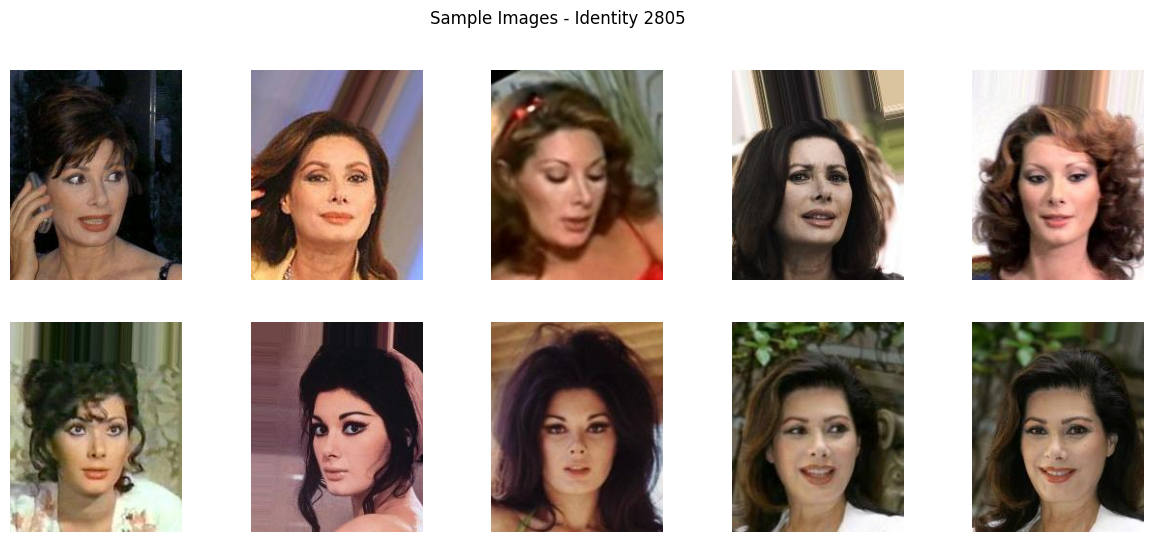

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, filename in zip(axes.ravel(), images[:10]):

    image_path = os.path.join(
        person_folder,
        filename
    )

    image = Image.open(image_path)

    ax.imshow(image)
    ax.axis("off")

plt.suptitle(
    f"Sample Images - Identity {identity}"
)

plt.show()

In [ ]:
import torch
from torchvision import transforms
from torchvision import datasets
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

print("PyTorch version:", torch.__version__)
print("Imports successful!")

PyTorch version: 2.11.0+cu128
Imports successful!


In [ ]:
from torchvision import transforms

train_transform = transforms.Compose([

    transforms.Resize((128, 128)),

    transforms.RandomResizedCrop(
        112,
        scale=(0.90, 1.0),
        ratio=(0.95, 1.05)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(5),

    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.10
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])


test_transform = transforms.Compose([

    transforms.Resize((112, 112)),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.5, 0.5, 0.5],
        [0.5, 0.5, 0.5]
    )
])

In [ ]:
from torchvision.datasets import ImageFolder

train_dir = "/content/face_dataset/train"
val_dir = "/content/face_dataset/val"
test_dir = "/content/face_dataset/test"

train_dataset = ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = ImageFolder(
    val_dir,
    transform=test_transform
)

test_dataset = ImageFolder(
    test_dir,
    transform=test_transform
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Classes:", len(train_dataset.classes))

Train: 2000
Validation: 500
Test: 500
Classes: 100


In [ ]:
print("Train classes:", len(train_dataset.classes))
print("Val classes:", len(val_dataset.classes))
print("Test classes:", len(test_dataset.classes))

print(
    "Train == Val:",
    train_dataset.classes == val_dataset.classes
)

print(
    "Train == Test:",
    train_dataset.classes == test_dataset.classes
)

Train classes: 100
Val classes: 100
Test classes: 100
Train == Val: True
Train == Test: True


In [ ]:


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10])

Images shape: torch.Size([32, 3, 112, 112])
Labels shape: torch.Size([32])
First 10 labels: tensor([54, 66, 77, 68, 87, 81, 19, 34, 44, 72])


In [ ]:
train_dataset = ImageFolder(
    root=train_dir,
    transform=train_transform
)

val_dataset = ImageFolder(
    root=val_dir,
    transform=test_transform
)

test_dataset = ImageFolder(
    root=test_dir,
    transform=test_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 2000
Validation images: 500
Testing images: 500


In [ ]:
print("Number of identities:",
      len(train_dataset.classes))

print("First 10 identity labels:")
print(train_dataset.classes[:10])

Number of identities: 100
First 10 identity labels:
['10001', '10047', '10117', '10174', '1043', '1231', '1468', '1590', '160', '1629']


In [ ]:
image_tensor, label = train_dataset[0]

print("Image tensor shape:", image_tensor.shape)
print("Label:", label)
print("Minimum value:", image_tensor.min().item())
print("Maximum value:", image_tensor.max().item())

Image tensor shape: torch.Size([3, 112, 112])
Label: 0
Minimum value: -0.9607843160629272
Maximum value: 0.9529411792755127


In [ ]:
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch labels shape:", labels.shape)

Batch image shape: torch.Size([32, 3, 112, 112])
Batch labels shape: torch.Size([32])


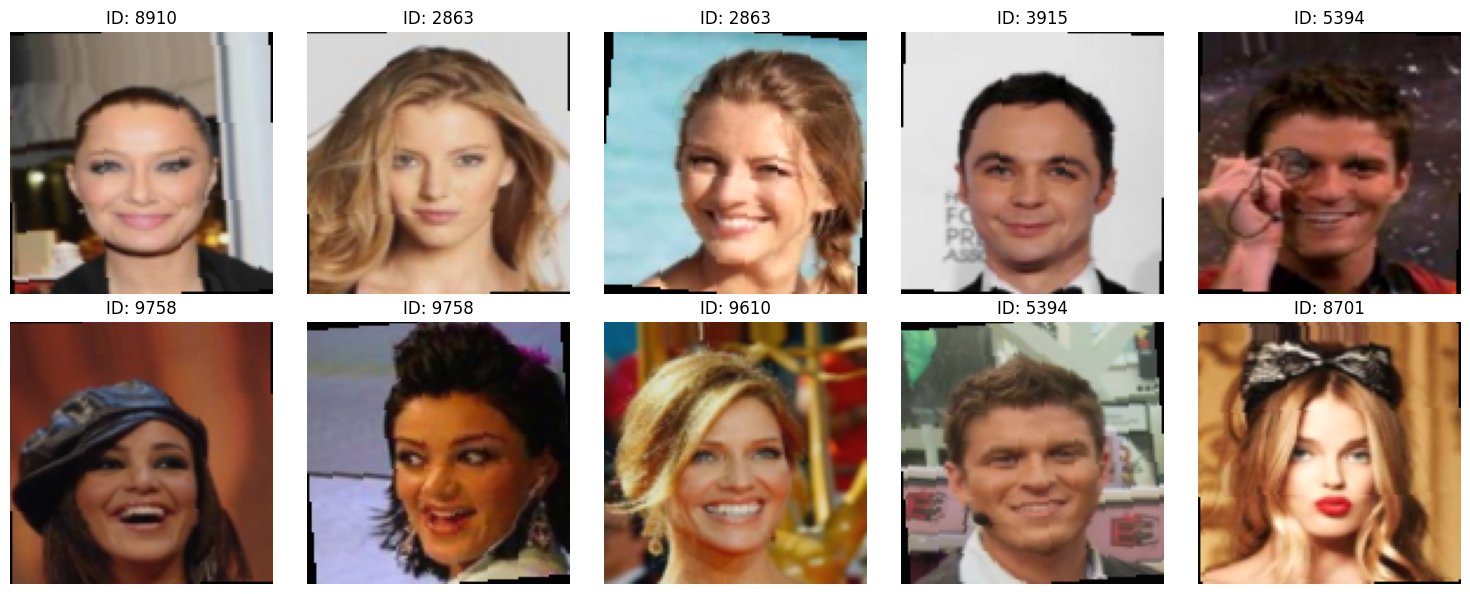

In [ ]:
#processed images

def show_images(images, labels, classes):

    images = images.clone()

    # Undo normalization
    images = images * 0.5 + 0.5

    images = images.permute(
        0, 2, 3, 1
    )

    images = images.clamp(0, 1)

    fig, axes = plt.subplots(
        2, 5,
        figsize=(15, 6)
    )

    for i, ax in enumerate(axes.ravel()):

        ax.imshow(images[i])

        ax.set_title(
            f"ID: {classes[labels[i]]}"
        )

        ax.axis("off")

    plt.tight_layout()
    plt.show()


show_images(
    images,
    labels,
    train_dataset.classes
)

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [ ]:
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

print("Images device:", images.device)
print("Labels device:", labels.device)

Images device: cuda:0
Labels device: cuda:0


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Number of classes:", len(train_dataset.classes))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Using device: cuda
GPU: Tesla T4
Number of classes: 100
Training images: 2000
Validation images: 500


In [ ]:
# baseline cnn



class BaselineCNN(nn.Module):

    def __init__(self, num_classes=100):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),

            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(256, 128),

            nn.ReLU(inplace=True),

            nn.Dropout(0.40),

            nn.Linear(128, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


model = BaselineCNN(num_classes=100).to(device)

print(model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 1

In [ ]:
num_classes = len(train_dataset.classes)

model = BaselineCNN(
    num_classes=num_classes
).to(device)

print(model)

BaselineCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (9): ReLU(inplace=True)
    (10): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (12): ReLU(inplace=True)
    (13): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (14): Conv2d(64, 1

In [ ]:
# parameters in classic cnn
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)

Total parameters: 1219972
Trainable parameters: 1219972


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Predictions
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [ ]:
def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    val_loss = running_loss / len(loader)
    val_accuracy = 100 * correct / total

    return val_loss, val_accuracy

In [ ]:
# re run if needed

import time

num_epochs = 50

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

start_time = time.time()

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

training_time = time.time() - start_time

print(f"\nTraining time: {training_time:.2f} seconds")
import json

history = {
    "train_loss": train_losses,
    "train_accuracy": train_accuracies,
    "val_loss": val_losses,
    "val_accuracy": val_accuracies
}

with open("/content/baseline_history.json", "w") as f:
    json.dump(history, f)

print("Training history saved.")

Epoch [1/50] | Train Loss: 4.6162 | Train Acc: 1.00% | Val Loss: 4.5581 | Val Acc: 2.20%
Epoch [2/50] | Train Loss: 4.5082 | Train Acc: 2.35% | Val Loss: 4.5103 | Val Acc: 2.40%
Epoch [3/50] | Train Loss: 4.4412 | Train Acc: 2.30% | Val Loss: 4.3667 | Val Acc: 3.20%
Epoch [4/50] | Train Loss: 4.3716 | Train Acc: 2.55% | Val Loss: 4.5048 | Val Acc: 1.00%
Epoch [5/50] | Train Loss: 4.3183 | Train Acc: 3.15% | Val Loss: 4.2610 | Val Acc: 4.80%
Epoch [6/50] | Train Loss: 4.2519 | Train Acc: 4.30% | Val Loss: 4.2825 | Val Acc: 3.80%
Epoch [7/50] | Train Loss: 4.2119 | Train Acc: 4.00% | Val Loss: 4.2443 | Val Acc: 5.40%
Epoch [8/50] | Train Loss: 4.1569 | Train Acc: 5.05% | Val Loss: 4.8862 | Val Acc: 4.60%
Epoch [9/50] | Train Loss: 4.1411 | Train Acc: 5.25% | Val Loss: 4.3797 | Val Acc: 4.80%
Epoch [10/50] | Train Loss: 4.0815 | Train Acc: 5.50% | Val Loss: 4.1118 | Val Acc: 7.00%
Epoch [11/50] | Train Loss: 4.0410 | Train Acc: 5.95% | Val Loss: 4.0917 | Val Acc: 7.20%
Epoch [12/50] | Tra

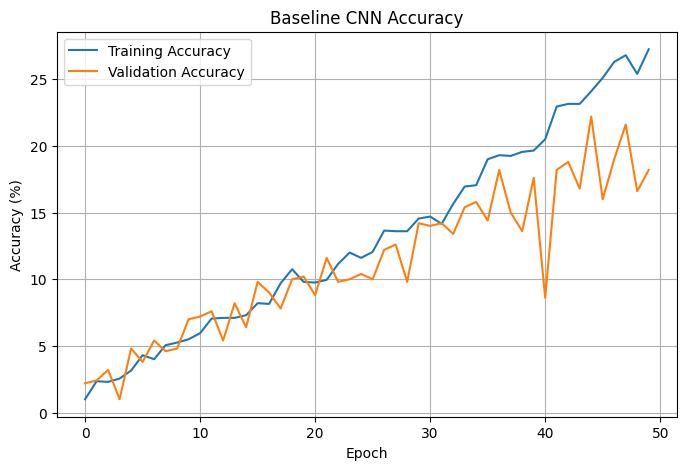

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    val_accuracies,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")


plt.ylabel("Accuracy (%)")
plt.title("Baseline CNN Accuracy")

plt.legend()
plt.grid()

plt.show()

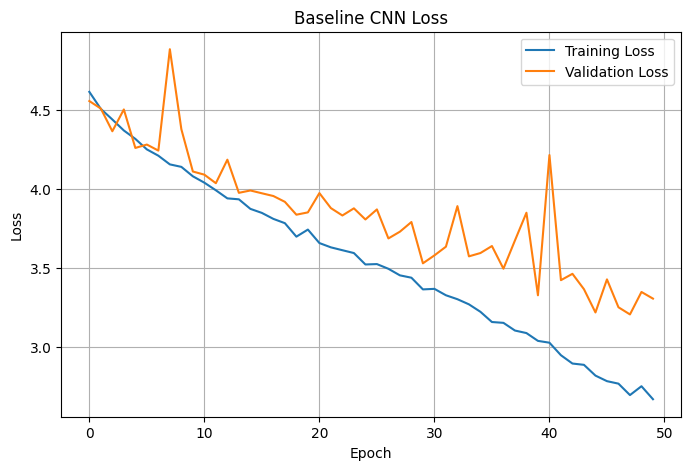

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline CNN Loss")

plt.legend()
plt.grid()

plt.show()

In [ ]:
os.makedirs("/content/models", exist_ok=True)

torch.save(
    model.state_dict(),
    "/content/models/baseline_cnn.pth"
)

print("Baseline CNN saved successfully.")

Baseline CNN saved successfully.


In [ ]:
import os

model_path = "/content/models/baseline_cnn.pth"

model_size_mb = (
    os.path.getsize(model_path) /
    (1024 * 1024)
)

print(
    f"Baseline model size: {model_size_mb:.2f} MB"
)

Baseline model size: 4.68 MB


In [ ]:
test_loss, test_accuracy = validate(
    model,
    test_loader,
    criterion,
    device
)

print("Baseline CNN Test Accuracy:",
      f"{test_accuracy:.2f}%")

Baseline CNN Test Accuracy: 17.20%


In [ ]:
print("Final Training Accuracy:",
      train_accuracies[-1])

print("Final Validation Accuracy:",
      val_accuracies[-1])

print("Final Training Loss:",
      train_losses[-1])

print("Final Validation Loss:",
      val_losses[-1])

Final Training Accuracy: 27.25
Final Validation Accuracy: 18.2
Final Training Loss: 2.6696404048374722
Final Validation Loss: 3.306802585721016


In [ ]:
print("Train classes:", len(train_dataset.classes))
print("Val classes:", len(val_dataset.classes))
print("Test classes:", len(test_dataset.classes))

print(
    "Train == Val:",
    train_dataset.classes == val_dataset.classes
)

print(
    "Train == Test:",
    train_dataset.classes == test_dataset.classes
)


from collections import Counter

train_counts = Counter(
    train_dataset.targets
)

val_counts = Counter(
    val_dataset.targets
)

test_counts = Counter(
    test_dataset.targets
)

print("Training images per class:",
      set(train_counts.values()))

print("Validation images per class:",
      set(val_counts.values()))

print("Testing images per class:",
      set(test_counts.values()))

Train classes: 100
Val classes: 100
Test classes: 100
Train == Val: True
Train == Test: True
Training images per class: {20}
Validation images per class: {5}
Testing images per class: {5}


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms, datasets
from torch.utils.data import DataLoader
import os
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

Device: cuda


In [ ]:
train_dir = "/content/face_dataset/train"
val_dir = "/content/face_dataset/val"
test_dir = "/content/face_dataset/test"

print("Train:", os.path.exists(train_dir))
print("Val:", os.path.exists(val_dir))
print("Test:", os.path.exists(test_dir))

Train: True
Val: True
Test: True


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomResizedCrop(
        224,
        scale=(0.85, 1.0),
        ratio=(0.95, 1.05)
    ),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
train_dataset = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=test_transform
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=test_transform
)

print("Number of classes:", len(train_dataset.classes))
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Number of classes: 100
Training images: 2000
Validation images: 500
Testing images: 500


In [ ]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
weights = models.MobileNet_V3_Small_Weights.DEFAULT

model = models.mobilenet_v3_small(
    weights=weights
)

model.classifier

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 96.0MB/s]


Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=1000, bias=True)
)

In [ ]:
num_features = model.classifier[3].in_features

model.classifier[3] = nn.Linear(
    num_features,
    100
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Linear(in_features=576, out_features=1024, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1024, out_features=100, bias=True)
)


In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", total_params)
print("Trainable parameters:", trainable_params)
print(
    "Approx model size:",
    total_params * 4 / (1024 ** 2),
    "MB"
)

Total parameters: 1620356
Trainable parameters: 1620356
Approx model size: 6.1811676025390625 MB


In [ ]:
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0005
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

In [ ]:
num_epochs = 30

best_val_acc = 0.0
best_epoch = 0

train_accuracies = []
val_accuracies = []

train_losses = []
val_losses = []

os.makedirs("/content/models", exist_ok=True)

start_time = time.time()

for epoch in range(num_epochs):

    # -------------------------
    # TRAIN
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (
                predicted == labels
            ).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    scheduler.step(val_acc)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.2f}%"
    )

    # -------------------------
    # SAVE BEST MODEL
    # -------------------------
    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "/content/models/mobilenet_v3_small_best.pth"
        )

        print(
            f"  ✓ Best model saved "
            f"(Val Acc: {val_acc:.2f}%)"
        )

training_time = time.time() - start_time

print("\nTraining completed.")
print("Best Validation Accuracy:", best_val_acc)
print("Best Epoch:", best_epoch)
print("Training Time:", training_time)

Epoch [1/30] Train Loss: 4.3213 Train Acc: 8.90% Val Loss: 4.1817 Val Acc: 10.00%
  ✓ Best model saved (Val Acc: 10.00%)
Epoch [2/30] Train Loss: 3.0078 Train Acc: 36.85% Val Loss: 3.1834 Val Acc: 26.60%
  ✓ Best model saved (Val Acc: 26.60%)
Epoch [3/30] Train Loss: 2.0003 Train Acc: 57.60% Val Loss: 2.4419 Val Acc: 42.80%
  ✓ Best model saved (Val Acc: 42.80%)
Epoch [4/30] Train Loss: 1.4521 Train Acc: 75.00% Val Loss: 2.3414 Val Acc: 45.60%
  ✓ Best model saved (Val Acc: 45.60%)
Epoch [5/30] Train Loss: 1.1700 Train Acc: 82.10% Val Loss: 2.0801 Val Acc: 54.40%
  ✓ Best model saved (Val Acc: 54.40%)
Epoch [6/30] Train Loss: 0.9314 Train Acc: 91.15% Val Loss: 2.0310 Val Acc: 56.80%
  ✓ Best model saved (Val Acc: 56.80%)
Epoch [7/30] Train Loss: 0.7940 Train Acc: 94.85% Val Loss: 1.9959 Val Acc: 57.20%
  ✓ Best model saved (Val Acc: 57.20%)
Epoch [8/30] Train Loss: 0.7265 Train Acc: 96.75% Val Loss: 1.9819 Val Acc: 58.40%
  ✓ Best model saved (Val Acc: 58.40%)
Epoch [9/30] Train Loss: 

In [ ]:
model.load_state_dict(
    torch.load(
        "/content/models/mobilenet_v3_small_best.pth",
        map_location=device
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (
            predicted == labels
        ).sum().item()

test_accuracy = 100 * correct / total

print("Best Validation Accuracy:", best_val_acc)
print("Test Accuracy:", test_accuracy)

Best Validation Accuracy: 67.2
Test Accuracy: 67.2


In [ ]:
criterion = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0003,
    weight_decay=0.0005
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2
)

print("Loss, optimizer and scheduler ready.")

Loss, optimizer and scheduler ready.


In [ ]:
num_epochs = 30

best_val_acc = 0.0
best_epoch = 0

train_accuracies = []
val_accuracies = []

train_losses = []
val_losses = []

os.makedirs("/content/models", exist_ok=True)

start_time = time.time()

for epoch in range(num_epochs):

    # =========================
    # TRAINING
    # =========================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    # Update learning rate
    scheduler.step(val_acc)

    # Store history
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2f}%"
    )

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "/content/models/mobilenet_v3_small_best.pth"
        )

        print(
            f"   ✓ Best model saved "
            f"(Validation Accuracy: {val_acc:.2f}%)"
        )

training_time = time.time() - start_time

print("\n" + "="*50)
print("TRAINING COMPLETED")
print("="*50)

print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Best Epoch: {best_epoch}")
print(f"Training Time: {training_time:.2f} seconds")

Epoch [01/30] | Train Loss: 0.5192 | Train Acc: 99.95% | Val Loss: 1.9638 | Val Acc: 60.80%
   ✓ Best model saved (Validation Accuracy: 60.80%)
Epoch [02/30] | Train Loss: 0.5216 | Train Acc: 99.90% | Val Loss: 1.8852 | Val Acc: 63.20%
   ✓ Best model saved (Validation Accuracy: 63.20%)
Epoch [03/30] | Train Loss: 0.5161 | Train Acc: 99.90% | Val Loss: 1.9005 | Val Acc: 62.40%
Epoch [04/30] | Train Loss: 0.5143 | Train Acc: 100.00% | Val Loss: 1.8471 | Val Acc: 64.20%
   ✓ Best model saved (Validation Accuracy: 64.20%)
Epoch [05/30] | Train Loss: 0.5088 | Train Acc: 100.00% | Val Loss: 1.8923 | Val Acc: 63.60%
Epoch [06/30] | Train Loss: 0.5031 | Train Acc: 100.00% | Val Loss: 1.8823 | Val Acc: 61.40%
Epoch [07/30] | Train Loss: 0.4992 | Train Acc: 100.00% | Val Loss: 1.8321 | Val Acc: 64.00%
Epoch [08/30] | Train Loss: 0.4910 | Train Acc: 100.00% | Val Loss: 1.7956 | Val Acc: 66.00%
   ✓ Best model saved (Validation Accuracy: 66.00%)
Epoch [09/30] | Train Loss: 0.4847 | Train Acc: 99.

In [ ]:
best_model_path = "/content/models/mobilenet_v3_small_best.pth"

model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print("="*50)
print("MOBILENETV3-SMALL TEST RESULT")
print("="*50)
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Test Accuracy: {test_accuracy:.2f}%")
print(f"Best Epoch: {best_epoch}")
print(f"Training Time: {training_time:.2f} seconds")

MOBILENETV3-SMALL TEST RESULT
Best Validation Accuracy: 69.00%
Test Accuracy: 71.80%
Best Epoch: 14
Training Time: 409.79 seconds


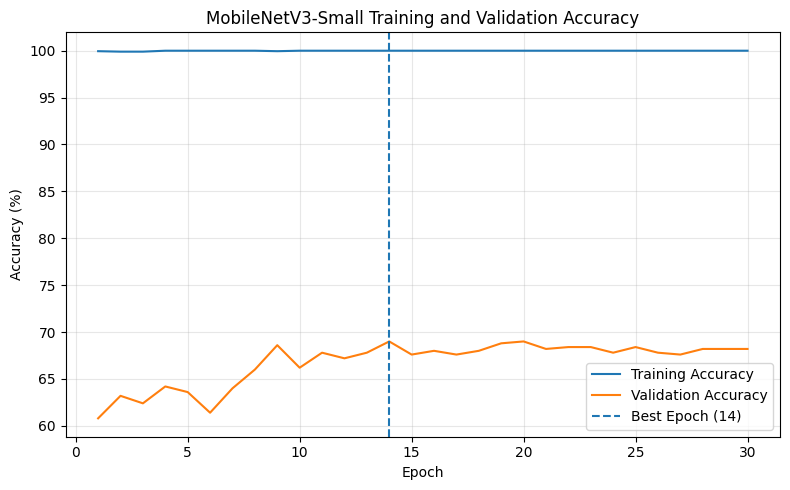

In [ ]:
import matplotlib.pyplot as plt

# ==============================
# ACCURACY CURVE
# ==============================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_accuracies) + 1),
    train_accuracies,
    label="Training Accuracy"
)

plt.plot(
    range(1, len(val_accuracies) + 1),
    val_accuracies,
    label="Validation Accuracy"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MobileNetV3-Small Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

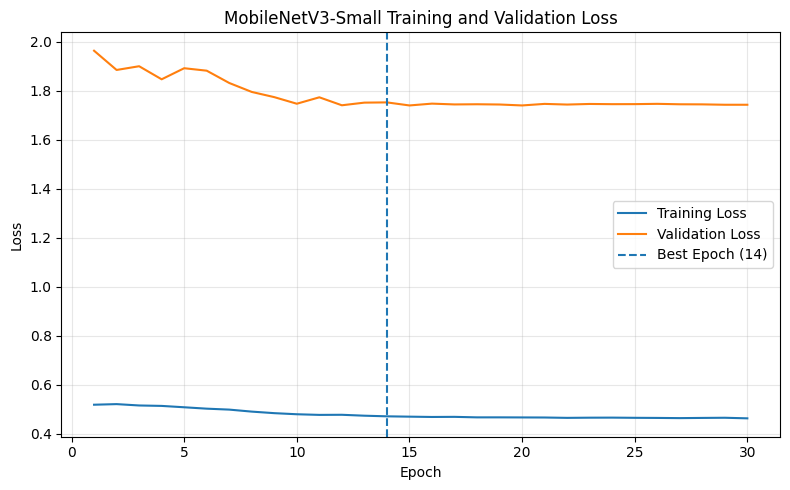

In [ ]:
# ==============================
# LOSS CURVE
# ==============================

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(train_losses) + 1),
    train_losses,
    label="Training Loss"
)

plt.plot(
    range(1, len(val_losses) + 1),
    val_losses,
    label="Validation Loss"
)

plt.axvline(
    best_epoch,
    linestyle="--",
    label=f"Best Epoch ({best_epoch})"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3-Small Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import classification_report
import numpy as np

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(outputs, dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Predictions collected:", len(all_predictions))
print("True labels collected:", len(all_labels))

Predictions collected: 500
True labels collected: 500


In [ ]:
report = classification_report(
    all_labels,
    all_predictions,
    target_names=test_dataset.classes,
    digits=4
)

print(report)

              precision    recall  f1-score   support

       10001     0.6667    0.4000    0.5000         5
       10047     0.5000    0.8000    0.6154         5
       10117     0.6667    0.8000    0.7273         5
       10174     0.3636    0.8000    0.5000         5
        1043     0.4286    0.6000    0.5000         5
        1231     1.0000    1.0000    1.0000         5
        1468     1.0000    0.6000    0.7500         5
        1590     0.8000    0.8000    0.8000         5
         160     1.0000    1.0000    1.0000         5
        1629     0.8333    1.0000    0.9091         5
        1634     0.6667    0.8000    0.7273         5
        1664     0.5000    0.2000    0.2857         5
        1686     1.0000    0.8000    0.8889         5
        1744     1.0000    0.6000    0.7500         5
        1815     0.6000    0.6000    0.6000         5
        1914     0.6667    0.4000    0.5000         5
        1985     0.6000    0.6000    0.6000         5
        2026     0.6667    

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

print(f"Test Accuracy : {test_accuracy:.4f}%")
print(f"Macro Precision: {precision:.4f}")
print(f"Macro Recall   : {recall:.4f}")
print(f"Macro F1-score : {f1:.4f}")

Test Accuracy : 71.8000%
Macro Precision: 0.7378
Macro Recall   : 0.7180
Macro F1-score : 0.7047


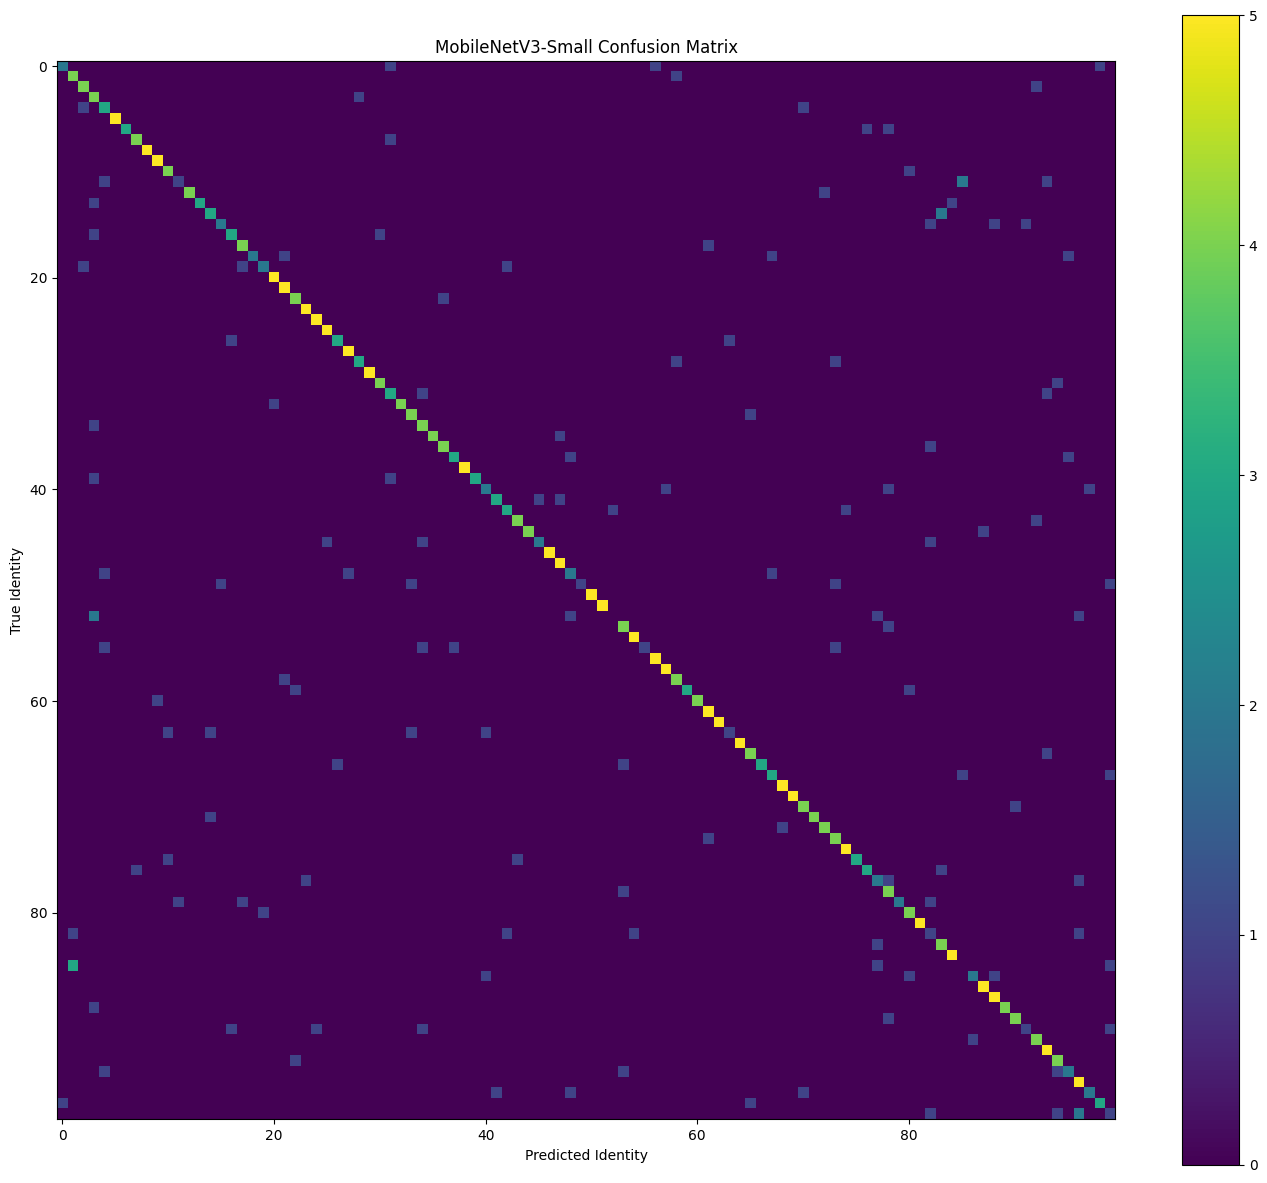

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(14, 12))

plt.imshow(cm, interpolation="nearest")

plt.title("MobileNetV3-Small Confusion Matrix")
plt.xlabel("Predicted Identity")
plt.ylabel("True Identity")

plt.colorbar()

plt.tight_layout()
plt.show()

In [ ]:
confusions = []

for i in range(len(cm)):

    for j in range(len(cm)):

        if i != j and cm[i, j] > 0:

            confusions.append(
                (
                    cm[i, j],
                    test_dataset.classes[i],
                    test_dataset.classes[j]
                )
            )

confusions = sorted(
    confusions,
    reverse=True
)

print("Top 20 Confusions")
print("=" * 60)

for count, true_class, predicted_class in confusions[:20]:

    print(
        f"True: {true_class:20s} "
        f"Predicted: {predicted_class:20s} "
        f"Count: {count}"
    )

Top 20 Confusions
True: 8701                 Predicted: 10047                Count: 3
True: 9935                 Predicted: 9646                 Count: 2
True: 5028                 Predicted: 10174                Count: 2
True: 1815                 Predicted: 8506                 Count: 2
True: 1664                 Predicted: 8701                 Count: 2
True: 9935                 Predicted: 9290                 Count: 1
True: 9935                 Predicted: 8457                 Count: 1
True: 9921                 Predicted: 6044                 Count: 1
True: 9921                 Predicted: 10001                Count: 1
True: 9758                 Predicted: 6187                 Count: 1
True: 9758                 Predicted: 4832                 Count: 1
True: 9758                 Predicted: 4373                 Count: 1
True: 9610                 Predicted: 9290                 Count: 1
True: 9610                 Predicted: 5096                 Count: 1
True: 9610                 Pre

In [ ]:
mobilenet_results = {
    "Model": "MobileNetV3-Small",
    "Parameters": 2542856,
    "Best Validation Accuracy (%)": best_val_acc,
    "Test Accuracy (%)": test_accuracy,
    "Best Epoch": best_epoch,
    "Training Time (seconds)": training_time,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

mobilenet_results

{'Model': 'MobileNetV3-Small',
 'Parameters': 2542856,
 'Best Validation Accuracy (%)': 69.0,
 'Test Accuracy (%)': 71.8,
 'Best Epoch': 14,
 'Training Time (seconds)': 409.7928285598755,
 'Precision': 0.7377593795093795,
 'Recall': 0.7180000000000001,
 'F1 Score': 0.7047344877344878}

In [ ]:
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print(
    "Approximate Parameter Size:",
    total_params * 4 / (1024 ** 2),
    "MB"
)

Total Parameters: 1620356
Trainable Parameters: 1620356
Approximate Parameter Size: 6.1811676025390625 MB


In [ ]:
import os

model_path = "/content/models/mobilenet_v3_small_best.pth"

file_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print("Saved Model:", model_path)
print(f"Checkpoint Size: {file_size_mb:.2f} MB")

Saved Model: /content/models/mobilenet_v3_small_best.pth
Checkpoint Size: 6.31 MB


In [ ]:
import time
import torch

model.eval()

# Take one image from test set
image, label = test_dataset[0]

image = image.unsqueeze(0).to(device)

# Warm-up
with torch.no_grad():
    for _ in range(20):
        _ = model(image)

if device.type == "cuda":
    torch.cuda.synchronize()

# Actual measurement
num_runs = 100

start_time = time.time()

with torch.no_grad():

    for _ in range(num_runs):
        _ = model(image)

        if device.type == "cuda":
            torch.cuda.synchronize()

end_time = time.time()

total_time = end_time - start_time

avg_time = total_time / num_runs

print("=" * 50)
print("MOBILENETV3-SMALL INFERENCE")
print("=" * 50)

print(f"Device: {device}")
print(f"Runs: {num_runs}")
print(f"Average inference time: {avg_time * 1000:.2f} ms")
print(f"Approximate FPS: {1 / avg_time:.2f}")

MOBILENETV3-SMALL INFERENCE
Device: cuda
Runs: 100
Average inference time: 10.50 ms
Approximate FPS: 95.23


In [ ]:
cpu_model = model.cpu()
cpu_model.eval()

cpu_image = image.cpu()

# Warm-up
with torch.no_grad():
    for _ in range(20):
        _ = cpu_model(cpu_image)

num_runs = 100

start_time = time.time()

with torch.no_grad():

    for _ in range(num_runs):
        _ = cpu_model(cpu_image)

end_time = time.time()

cpu_total_time = end_time - start_time

cpu_avg_time = cpu_total_time / num_runs

print("=" * 50)
print("CPU INFERENCE")
print("=" * 50)

print(f"Average inference time: {cpu_avg_time * 1000:.2f} ms")
print(f"Approximate FPS: {1 / cpu_avg_time:.2f}")

CPU INFERENCE
Average inference time: 16.94 ms
Approximate FPS: 59.03


In [ ]:
mobilenet_final_results = {
    "Model": "MobileNetV3-Small",
    "Parameters": total_params,
    "Model Size (MB)": file_size_mb,
    "Validation Accuracy (%)": best_val_acc,
    "Test Accuracy (%)": test_accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1,
    "Best Epoch": best_epoch,
    "Training Time (s)": training_time,
    "GPU Inference (ms)": avg_time * 1000,
    "GPU FPS": 1 / avg_time,
    "CPU Inference (ms)": cpu_avg_time * 1000,
    "CPU FPS": 1 / cpu_avg_time
}

for key, value in mobilenet_final_results.items():
    print(f"{key}: {value}")

Model: MobileNetV3-Small
Parameters: 1620356
Model Size (MB): 6.312674522399902
Validation Accuracy (%): 69.0
Test Accuracy (%): 71.8
Precision: 0.7377593795093795
Recall: 0.7180000000000001
F1 Score: 0.7047344877344878
Best Epoch: 14
Training Time (s): 409.7928285598755
GPU Inference (ms): 10.501229763031006
GPU FPS: 95.22694223113223
CPU Inference (ms): 16.9403338432312
CPU FPS: 59.030713872239716
